# Day 04 | Seaborn: Explore Table Data

**KGP Talkie | Day 04**

We use pandas DataFrames and Matplotlib labels from earlier lessons. If a library is missing, run `%pip install pandas matplotlib seaborn` in a new cell, then restart the kernel.

Run the cells in order. Each new term is explained before we use it.

## Learning path

1. What is Seaborn?
2. Tidy data and variable types
3. Themes and the data, x, and y parameters
4. hue, style, and palette
5. countplot: counting rows in each category
6. barplot: calculating a group summary
7. histplot: distributions and bin edges
8. boxplot: median, quartiles, and spread
9. stripplot: showing individual observations
10. heatmap: values represented by color
11. Axes, layout, and saving
12. Practice

## 1. What is Seaborn?

**Seaborn** is a Python library for statistical data visualisation. It builds on Matplotlib and works with named columns in a DataFrame. It can show individual values, distributions, and summaries such as group means.

We use pandas to hold the data, Seaborn to draw plots, and Matplotlib to set titles and display the result.

In [1]:
import pandas as pd

In [2]:
import seaborn as sns

In [3]:
import matplotlib.pyplot as plt

## 2. Tidy data and variable types

In **tidy data**, each row is an observation and each column is a variable. Our observation is one student. `hours` and `score` are **numeric variables**. `group` is a **categorical variable**, which means it holds a label.

The small dataset is invented for practice. This notebook creates it directly, so it needs no remote dataset.

In [4]:
students = pd.DataFrame({
    'student_id': [101, 102, 103, 104, 105, 106, 107, 108],
    'name': ['Asha', 'Bilal', 'Chen', 'Diya', 'Eshan', 'Fatima', 'Gita', 'Hari'],
    'group': ['A', 'B', 'A', 'B', 'A', 'B', 'A', 'B'],
    'hours': [1, 2, 3, 4, 2, 5, 3, 4],
    'practice': [2, 4, 5, 7, 3, 8, 6, 6],
    'score': [45, 55, 65, 78, 52, 90, 68, 74]
})

In [5]:
students.head()

,student_id,name,group,hours,practice,score
0,101,Asha,A,1,2,45
1,102,Bilal,B,2,4,55
2,103,Chen,A,3,5,65
3,104,Diya,B,4,7,78
4,105,Eshan,A,2,3,52


## 3. Themes and the data, x, and y parameters

A **theme** sets plot style defaults such as background and grid. `whitegrid` adds a grid on a white background.

In an axes-level Seaborn plotting function, `data` is the DataFrame, and `x` and `y` are column names. Seaborn looks up the values in those columns.

In [6]:
sns.set_theme(style='whitegrid')

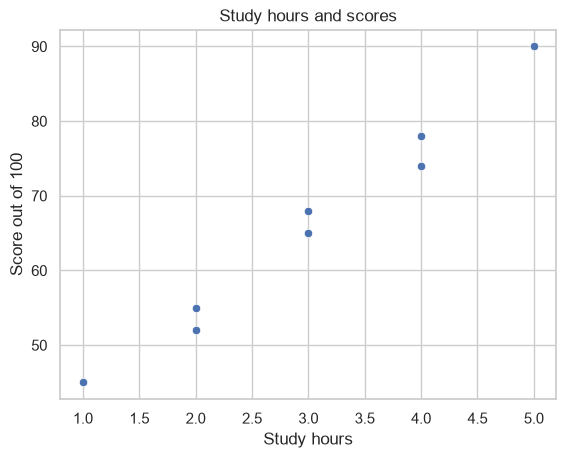

In [7]:
sns.scatterplot(data=students, x='hours', y='score')
plt.title('Study hours and scores')
plt.xlabel('Study hours')
plt.ylabel('Score out of 100')
plt.show()

## 4. hue, style, and palette

A **semantic mapping** connects a data column to a visible feature. `hue` maps a column to color. `style` maps a column to marker shape. A **palette** is a set of colors.

We use color and shape for group A and B. Shape gives another clue when colors are hard to tell apart. `s=100` sets the marker area.

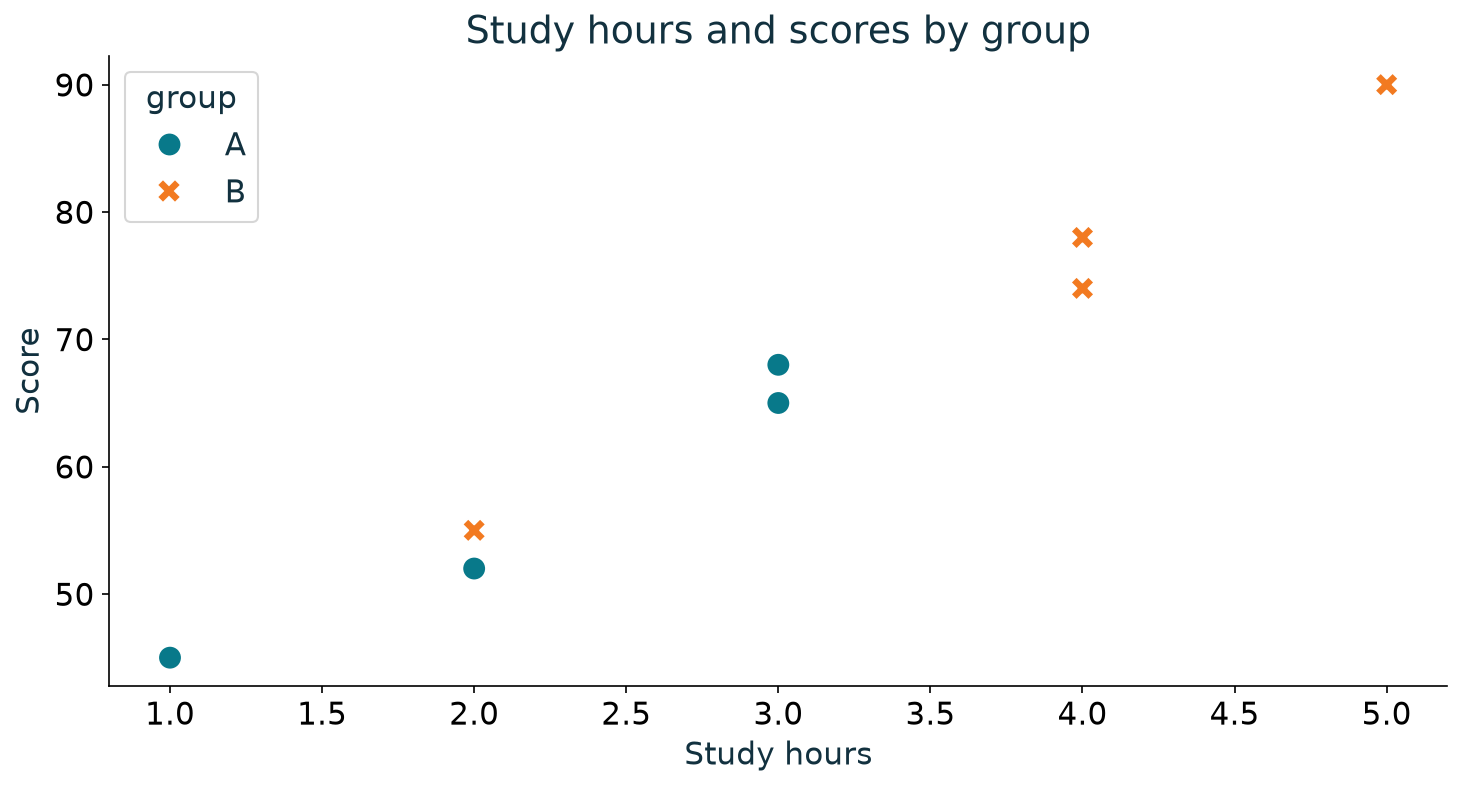

Each point is a student. Color and marker shape identify the class group.

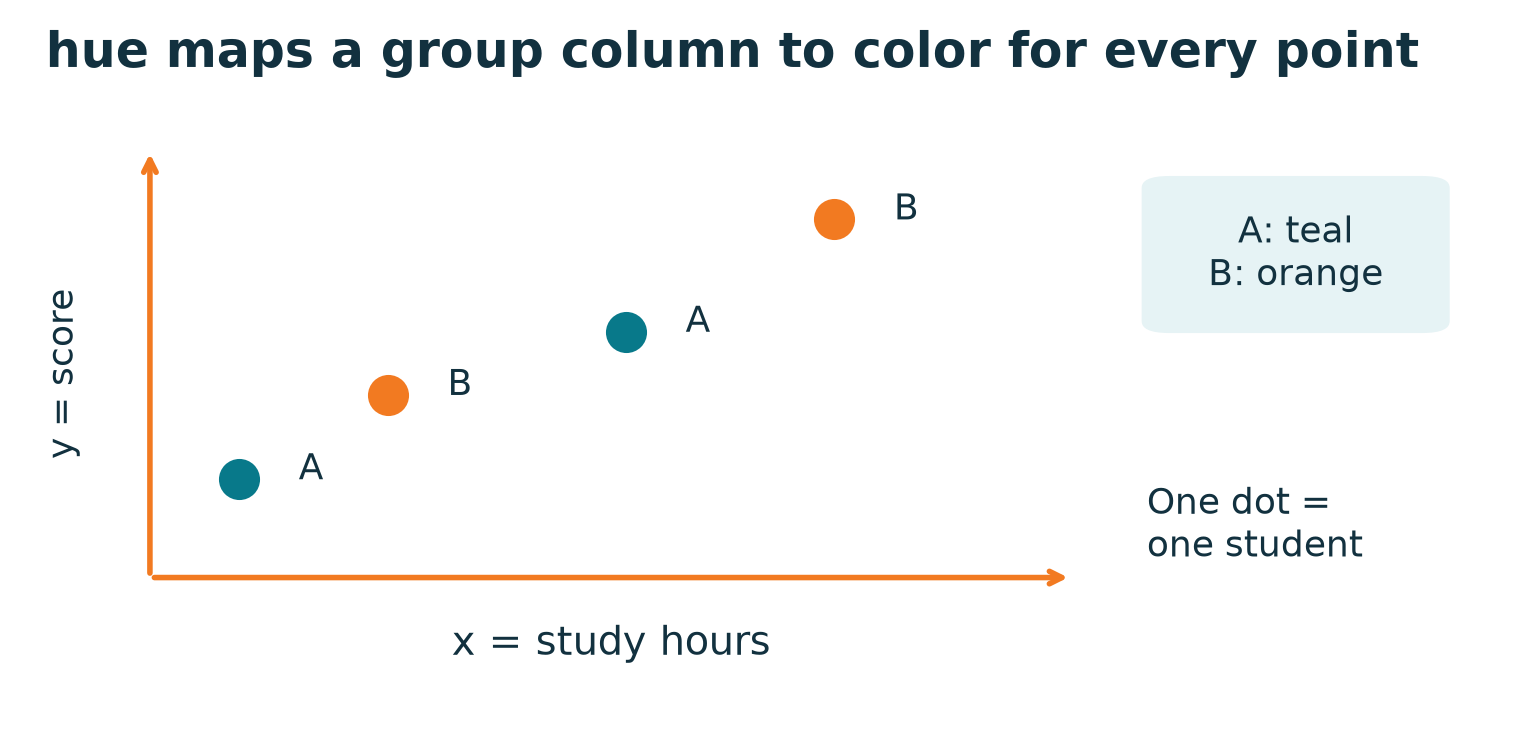

x and y choose the point position. hue uses the group label to choose its color.

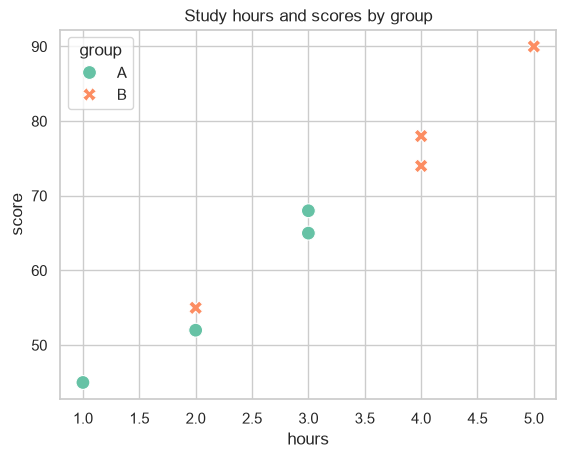

In [8]:
# x and y choose positions. hue uses the group column to choose colors.
sns.scatterplot(data=students, x='hours', y='score', hue='group', style='group', palette='Set2', s=100)
plt.title('Study hours and scores by group')
plt.show()

## 5. countplot: counting rows in each category

A **count plot** counts observations for each category. It needs the category column, but it does not need a numeric y column. Here each bar counts students in one group.

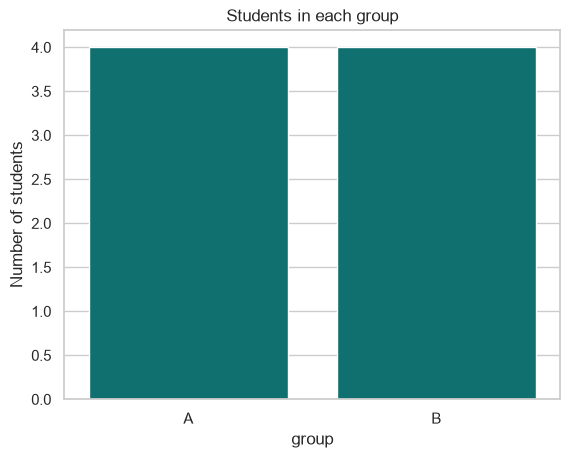

In [9]:
sns.countplot(data=students, x='group', color='teal')
plt.title('Students in each group')
plt.ylabel('Number of students')
plt.show()

## 6. barplot: calculating a group summary

A Seaborn **bar plot** calculates a summary of y for each category on x. Its default **estimator**, the function used for the summary, is the mean.

`errorbar=None` hides the uncertainty interval for this small descriptive exercise. It does not prove the means are certain or representative of all students.

A count plot answers how many students; a bar plot of scores answers what their mean score is.

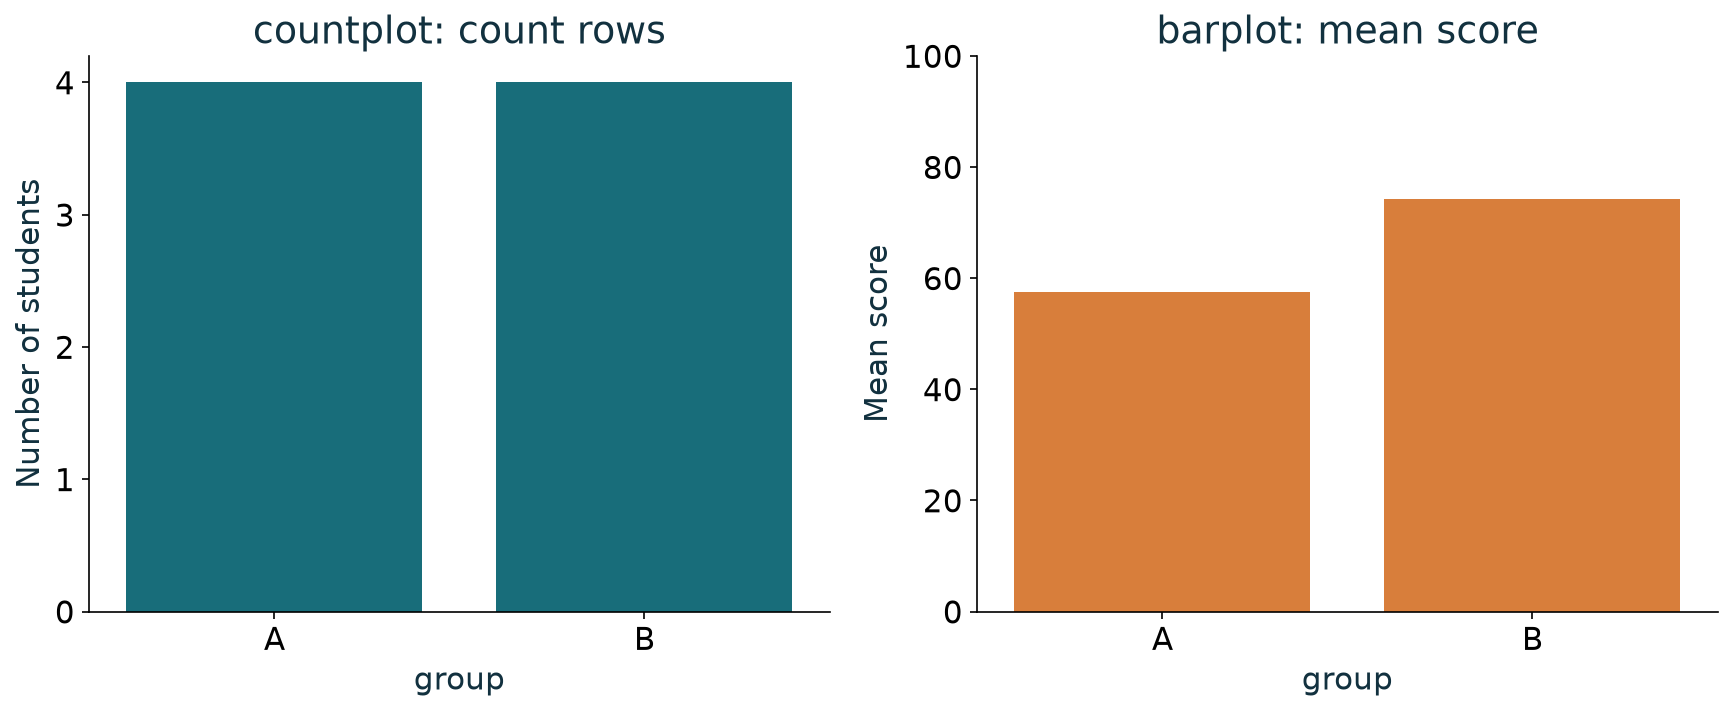

Both plots use group A and B, but their y axes measure different things.

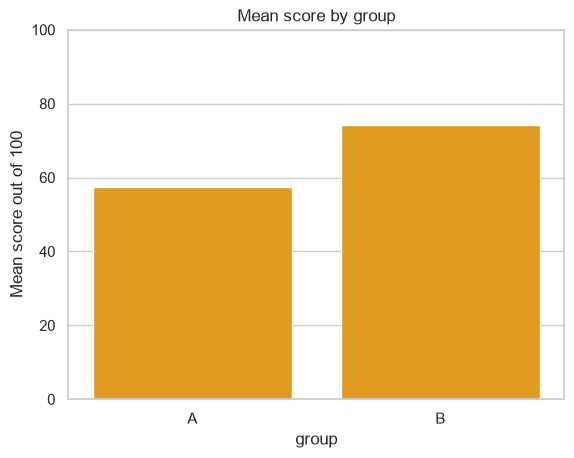

In [10]:
sns.barplot(data=students, x='group', y='score', errorbar=None, color='orange')
plt.title('Mean score by group')
plt.ylabel('Mean score out of 100')
plt.ylim(0, 100)
plt.show()

## 7. histplot: distributions and bin edges

`histplot()` displays a **distribution**, showing how a numeric variable is spread. `bins` can be a number of intervals or a list of exact edges.

We reuse four clear score intervals so we can compare the result with Day 4.

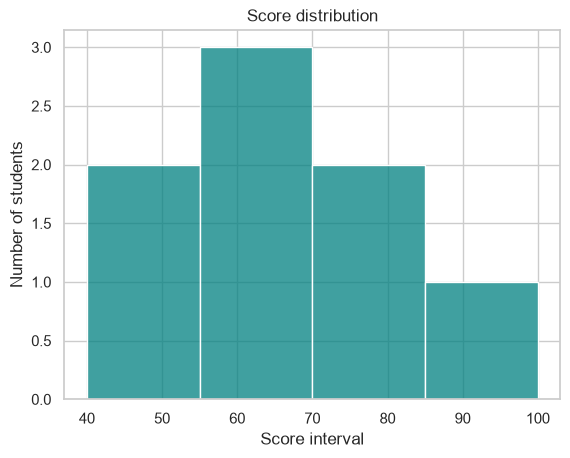

In [11]:
sns.histplot(data=students, x='score', bins=[40, 55, 70, 85, 100], color='teal')
plt.title('Score distribution')
plt.xlabel('Score interval')
plt.ylabel('Number of students')
plt.show()

## 8. boxplot: median, quartiles, and spread

A **box plot** summarises a numeric distribution.

| Part | Meaning |
|---|---|
| Line in the box | Median, the middle value |
| Bottom and top of the box | First and third quartiles, Q1 and Q3 |
| Box height | Interquartile range, IQR = Q3 - Q1 |
| Whiskers | By default, reach the most distant values within 1.5 IQR of the box |
| Separate points | Values beyond the whiskers; these are not automatically errors |

With just four scores in each group, individual points help us see the actual data.

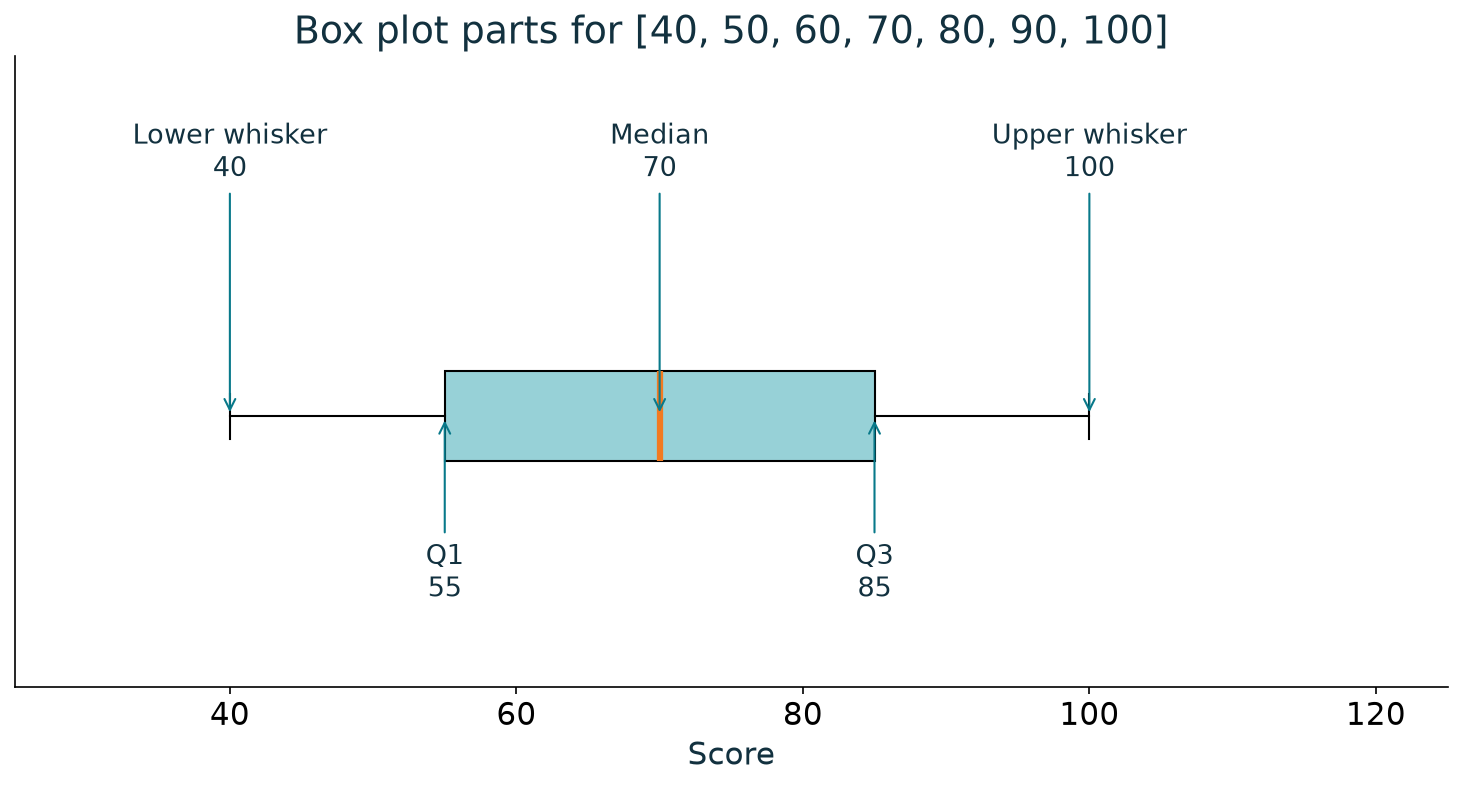

This separate seven-score example labels the median, quartiles, and whiskers. The median is 70 and the box runs from 55 to 85.

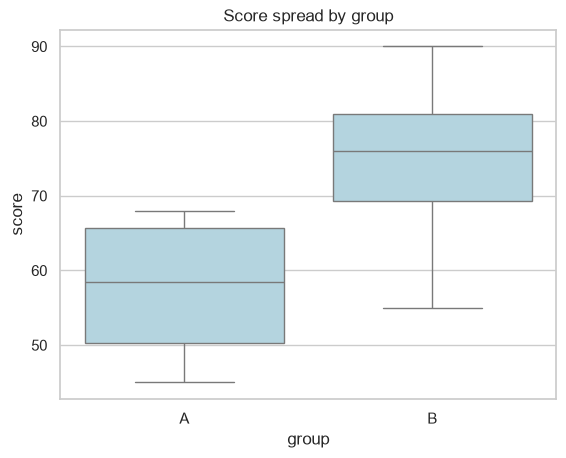

In [12]:
sns.boxplot(data=students, x='group', y='score', color='lightblue')
plt.title('Score spread by group')
plt.show()

## 9. stripplot: showing individual observations

A **strip plot** draws one point for every observation in a category. **Jitter** moves points slightly sideways to reduce overlap. Here `jitter=False` keeps the positions fixed, and our example has distinct scores.

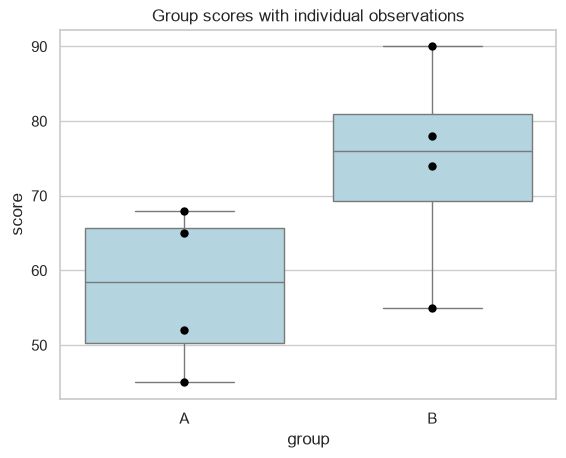

In [13]:
sns.boxplot(data=students, x='group', y='score', color='lightblue')
sns.stripplot(data=students, x='group', y='score', color='black', size=6, jitter=False)
plt.title('Group scores with individual observations')
plt.show()

## 10. heatmap: values represented by color

A **heatmap** maps each table value to a color. Rows and columns still carry labels. A **colorbar** shows which number matches each color.

Our quiz columns use the same score scale, so their colors can be compared directly.

In [14]:
quiz_scores = pd.DataFrame({'Quiz 1': [60, 75, 80], 'Quiz 2': [70, 72, 90]}, index=['Asha', 'Bilal', 'Chen'])

In [15]:
quiz_scores

,Quiz 1,Quiz 2
Asha,60,70
Bilal,75,72
Chen,80,90


| Parameter | Meaning |
|---|---|
| `annot=True` | Write each value inside its cell |
| `fmt="d"` | Display integer values |
| `cmap="YlGnBu"` | Use a yellow, green, blue color map |
| `vmin=0`, `vmax=100` | Fix the shared score scale |
| `linewidths=1` | Add lines between cells |

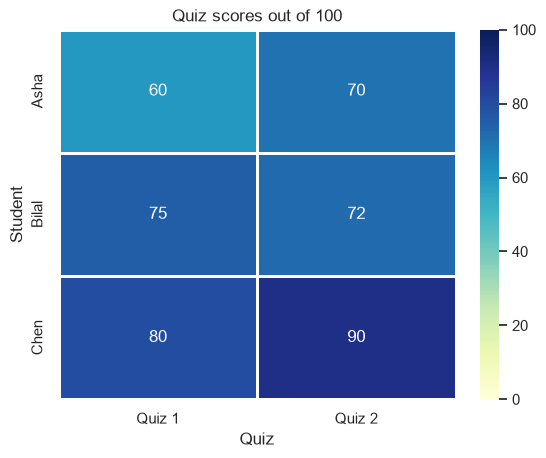

In [16]:
sns.heatmap(quiz_scores, annot=True, fmt='d', cmap='YlGnBu', vmin=0, vmax=100, linewidths=1)
plt.title('Quiz scores out of 100')
plt.xlabel('Quiz')
plt.ylabel('Student')
plt.show()

## 11. Axes, layout, and saving

Seaborn axes-level functions can draw into a Matplotlib Axes supplied using `ax`. That lets us choose the size, arrange subplots, and save the resulting Figure.

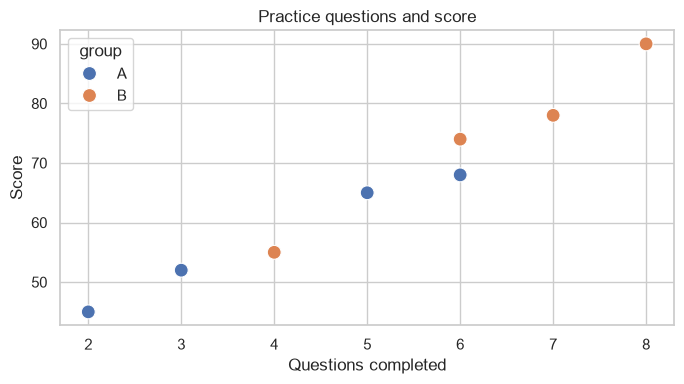

In [17]:
# x and y choose positions. hue uses the group column to choose colors.
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=students, x='practice', y='score', hue='group', s=100, ax=ax)
ax.set(title='Practice questions and score', xlabel='Questions completed', ylabel='Score')
fig.tight_layout()
fig.savefig('day-05-practice-scores.png', dpi=150)
plt.show()

## 12. Practice

1. Make a scatter plot with practice on x and score on y. Use group for hue.
2. Make a count plot of group. Explain what the bar height means.
3. Compare that count plot with the mean-score bar plot.
4. Explain why the heatmap fixes its color range at 0 to 100.

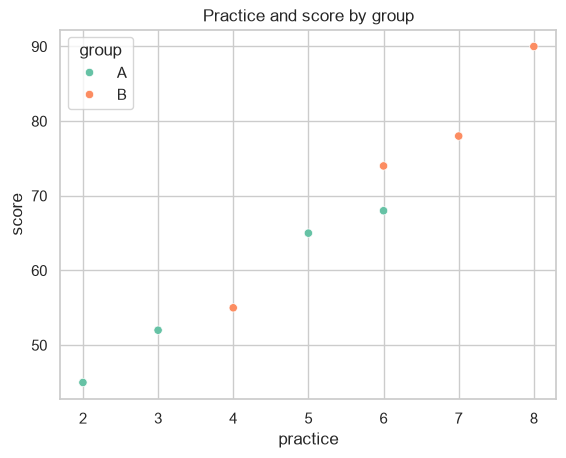

In [18]:
# x and y choose positions. hue uses the group column to choose colors.
sns.scatterplot(data=students, x='practice', y='score', hue='group', palette='Set2')
plt.title('Practice and score by group')
plt.show()